## MLPI Textbook — Chapter 3 companion notebook

# Regression: Predicting Spindle Power on a CNC Mill

### Linear regression from scratch, normal equations, robust fitting, multiple regression, regularisation and locally weighted regression

---

A machining cell logs every cut its 3-axis mill makes: the cutting parameters the CAM program
asked for, the material, the state of the tool — and the **spindle power** the drive actually
drew. Process engineers want a model that predicts that power *before* the cut runs, so they
can

* flag NC programs that will overload the spindle,
* estimate energy per part for costing, and
* spot cuts whose measured power is far above the prediction — an early sign of a worn or
  chipped tool.

Predicting a continuous number is **regression**. This notebook builds regression models from
the simplest possible one — a straight line through one feature — up to multi-feature models
with physics-informed features and regularisation.

### What you will be able to do afterwards

1. Fit a straight line by **gradient descent** and by the **normal equations**, and explain why
   both give the same answer.
2. Detect and survive **outliers** with RANSAC.
3. Build a **multiple regression** model, read its residual plot, and score it with MSE, MAE and $R^2$.
4. Show why **feature engineering from physics** beats adding more raw features.
5. Use **Ridge** and **Lasso** regularisation, and **locally weighted regression** for a
   strongly nonlinear curve (joint friction of a robot axis).

| § | topic |
|---|---|
| 1 | the data — a simulated machining log |
| 2 | exploring the data |
| 3 | simple linear regression with gradient descent |
| 4 | the normal equations and scikit-learn |
| 5 | outliers and RANSAC |
| 6 | multiple regression and evaluation |
| 7 | features from physics |
| 8 | regularisation: Ridge and Lasso |
| 9 | nonlinear relationships: locally weighted regression on a friction curve |

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

# plot style shared by every chapter of the book
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "font.size": 10, "legend.frameon": False,
})
BLUE, ORANGE, AQUA, YELLOW, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781"
CLASS_COLORS = [BLUE, ORANGE, AQUA]

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)


def savefig(name):
    """Save the current figure for the chapter text (figures/<name>.png)."""
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")

python       3.13.18
numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1


---
## 1. The data

Synthetic but physically built, so it runs without a download. The physics is the standard
machining power model: the power that goes into cutting is the **specific cutting energy** $u$ of
the material (J/mm³) times the **material removal rate** (MRR, mm³/s),
$$P_\text{cut} = u\cdot \text{MRR},\qquad \text{MRR} = a_p\, a_e\, v_f ,$$
with axial depth $a_p$, radial width $a_e$ and feed rate $v_f$. The spindle also draws an
**idle power** that grows with speed (bearings, fan, drive losses), a worn tool needs more energy
per mm³, and the drive is about 85 % efficient. About 3 % of the logged cuts **chattered** —
a vibration instability that inflates the measured power.

| column | meaning | unit |
|---|---|---|
| `material` | `aluminium` (6061) or `steel` (1045) | — |
| `spindle_rpm` | spindle speed | rev/min |
| `feed_mm_min` | table feed rate | mm/min |
| `depth_mm` | axial depth of cut $a_p$ | mm |
| `width_mm` | radial width of cut $a_e$ | mm |
| `tool_wear_um` | flank wear VB measured at the last tool check | µm |
| `coolant` | flood coolant on (1) / off (0) | — |
| **`power_W`** | **measured spindle power (target)** | W |

In [2]:
U_SPECIFIC = {"aluminium": 0.8, "steel": 2.6}     # J/mm^3, specific cutting energy
DRIVE_EFF = 0.85


def make_machining_log(n=500, seed=21):
    rng = np.random.default_rng(seed)
    steel = rng.random(n) < 0.4
    rpm = np.where(steel, rng.uniform(1500, 4000, n), rng.uniform(6000, 12000, n))
    feed = np.where(steel, rng.uniform(200, 900, n), rng.uniform(800, 3000, n))
    depth = rng.uniform(0.5, 4.0, n)
    width = rng.uniform(2.0, 12.0, n)
    wear = rng.uniform(0, 250, n)
    coolant = (rng.random(n) < 0.7).astype(int)

    mrr = depth * width * feed / 60.0                                # mm^3/s
    u = np.where(steel, U_SPECIFIC["steel"], U_SPECIFIC["aluminium"])
    p_cut = u * mrr * (1 + 0.0012 * wear) * (1 - 0.03 * coolant) / DRIVE_EFF
    p_idle = 180 + 0.035 * rpm
    power = (p_idle + p_cut) * rng.normal(1.0, 0.04, n)              # 4 % measurement noise
    chatter = rng.random(n) < 0.03
    power[chatter] *= rng.uniform(1.4, 2.2, chatter.sum())           # chatter inflates power

    return pd.DataFrame(dict(material=np.where(steel, "steel", "aluminium"),
                             spindle_rpm=rpm, feed_mm_min=feed, depth_mm=depth,
                             width_mm=width, tool_wear_um=wear, coolant=coolant,
                             power_W=power, chatter=chatter))


log = make_machining_log()
# `chatter` is ground truth the real cell would NOT have; we keep it only to check RANSAC later.
print(log.shape)
log.head()

(500, 9)


,material,spindle_rpm,feed_mm_min,depth_mm,width_mm,tool_wear_um,coolant,power_W,chatter
0,aluminium,11342.523728,1341.640529,3.665218,8.566910,209.149804,1,1377.318863,False
1,aluminium,9388.307771,1827.813979,2.993105,8.916023,192.246338,1,1460.852336,False
2,aluminium,7809.893621,2765.302012,1.901664,7.333504,112.360714,1,1185.931225,False
3,steel,3224.384863,718.818054,2.135424,9.131804,193.041093,0,1146.352619,False
4,aluminium,8632.314377,2922.718010,2.139150,2.478007,47.386233,0,683.141503,False


In [3]:
log.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
spindle_rpm,500.0,6538.2,3415.1,1527.7,3181.9,6941.3,9699.8,11976.8
feed_mm_min,500.0,1345.2,833.5,202.8,619.5,1156.8,2014.5,2994.3
depth_mm,500.0,2.3,1.0,0.5,1.4,2.3,3.2,4.0
width_mm,500.0,7.3,2.9,2.0,4.8,7.5,9.8,12.0
tool_wear_um,500.0,125.8,74.1,0.4,56.6,127.2,190.5,249.6
coolant,500.0,0.7,0.5,0.0,0.0,1.0,1.0,1.0
power_W,500.0,995.8,474.0,293.3,650.7,888.6,1292.0,3782.6


---
## 2. Exploring the data

Before fitting anything, look. A scatter-plot matrix and a correlation matrix are the two
standard first views. (The original book used the `mlxtend` package for both; plain
matplotlib and pandas are enough.)

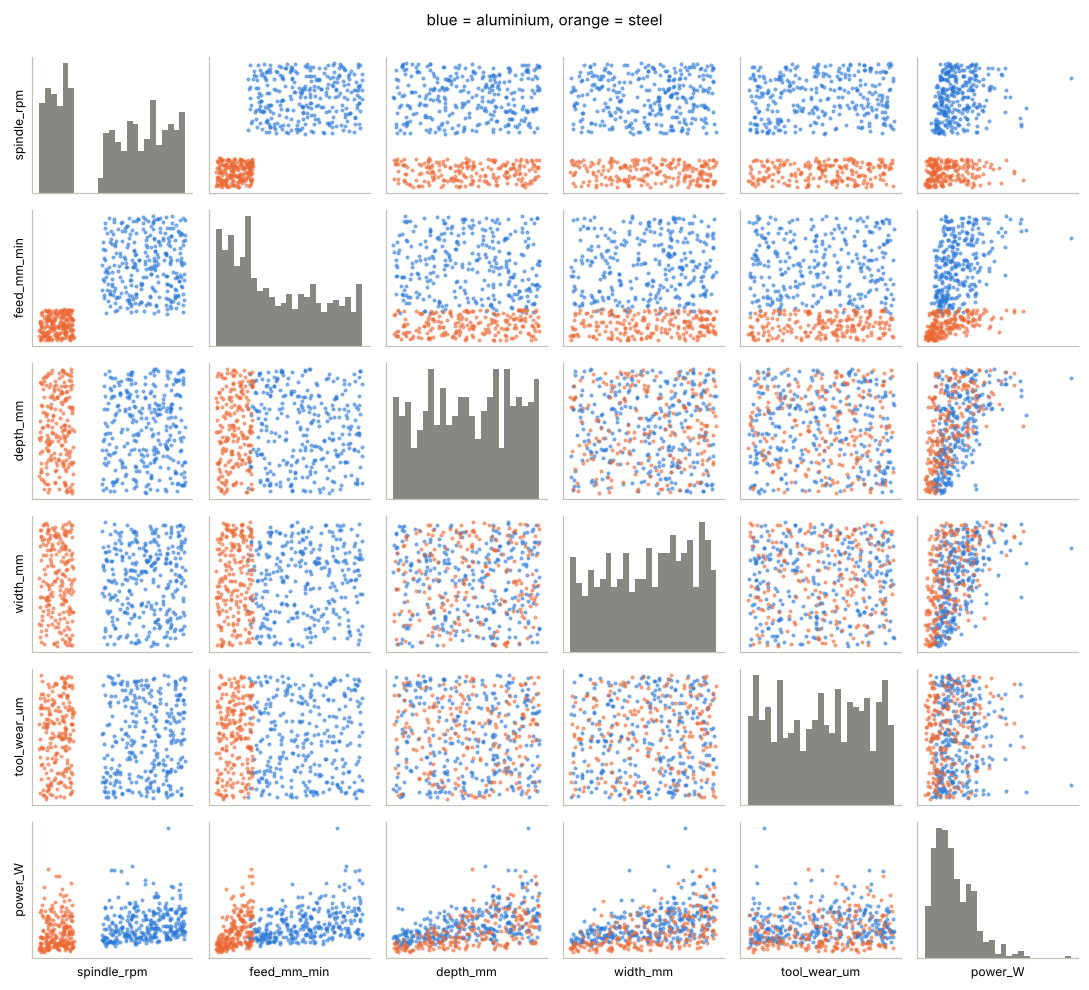

In [4]:
cols = ["spindle_rpm", "feed_mm_min", "depth_mm", "width_mm", "tool_wear_um", "power_W"]
is_steel = (log.material == "steel").to_numpy()
fig, axes = plt.subplots(len(cols), len(cols), figsize=(10, 9))
for i, ci in enumerate(cols):
    for j, cj in enumerate(cols):
        ax = axes[i, j]
        if i == j:
            ax.hist(log[ci], bins=25, color=MUTED)
        else:
            ax.scatter(log[cj][~is_steel], log[ci][~is_steel], s=3, color=BLUE, alpha=0.5)
            ax.scatter(log[cj][is_steel], log[ci][is_steel], s=3, color=ORANGE, alpha=0.5)
        ax.set_xticks([]); ax.set_yticks([])
        if i == len(cols) - 1: ax.set_xlabel(cj, fontsize=8)
        if j == 0: ax.set_ylabel(ci, fontsize=8)
fig.suptitle("blue = aluminium, orange = steel", y=0.995, fontsize=10)
plt.tight_layout(); savefig("ch03_scatter_matrix"); plt.show()

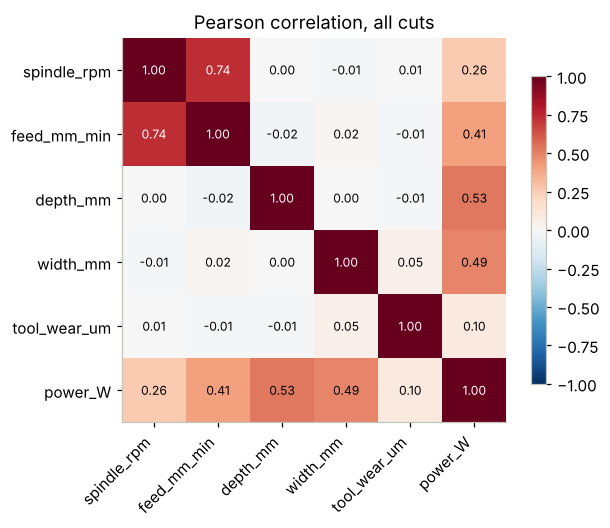

In [5]:
corr = log[cols].corr()
fig, ax = plt.subplots(figsize=(5.8, 4.8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right"); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Pearson correlation, all cuts")
plt.tight_layout(); savefig("ch03_corr"); plt.show()

Two lessons from these plots, and both are about **physics hiding behind the statistics**:

* `spindle_rpm` and `feed_mm_min` correlate strongly with each other — not because one causes
  the other, but because aluminium is cut fast and steel slow. The material is a **confounder**.
* No single raw column correlates strongly with power. Power depends on the **product**
  depth × width × feed, and a correlation coefficient only measures *linear* association with
  one variable at a time.

---
## 3. Simple linear regression with gradient descent

Start with the simplest case: aluminium cuts only, one engineered feature — the material removal
rate in cm³/min — and the model
$$\hat y = w\,x + b .$$
We choose $w, b$ to minimise the **mean squared error**
$$L(w,b) = \frac{1}{2n}\sum_{i=1}^n\big(y^{(i)} - \hat y^{(i)}\big)^2 .$$
The gradients are
$$\frac{\partial L}{\partial w} = -\frac1n\sum_i (y^{(i)}-\hat y^{(i)})\,x^{(i)},\qquad
\frac{\partial L}{\partial b} = -\frac1n\sum_i (y^{(i)}-\hat y^{(i)}).$$

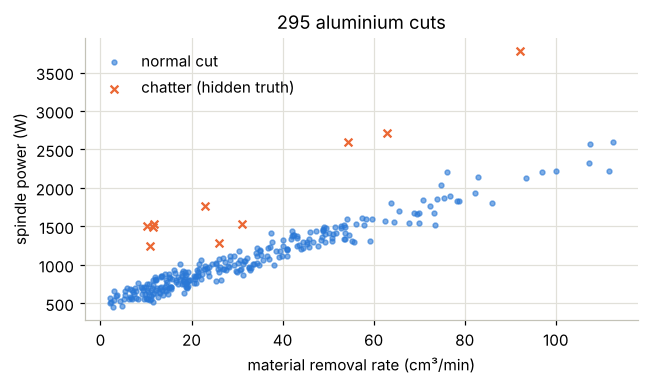

In [6]:
log["mrr_cm3_min"] = log.depth_mm * log.width_mm * log.feed_mm_min / 1000.0
alu = log[log.material == "aluminium"].reset_index(drop=True)

X1 = alu[["mrr_cm3_min"]].to_numpy()
y1 = alu["power_W"].to_numpy()

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.scatter(X1[~alu.chatter], y1[~alu.chatter], s=10, color=BLUE, alpha=0.6, label="normal cut")
ax.scatter(X1[alu.chatter], y1[alu.chatter], s=26, color=ORANGE, marker="x", label="chatter (hidden truth)")
ax.set_xlabel("material removal rate (cm³/min)"); ax.set_ylabel("spindle power (W)")
ax.legend(); ax.set_title(f"{len(alu)} aluminium cuts")
plt.tight_layout(); savefig("ch03_alu_scatter"); plt.show()

In [7]:
class LinearRegressionGD:
    """Ordinary least squares fitted with full-batch gradient descent."""

    def __init__(self, eta=0.01, n_iter=50, random_state=1):
        self.eta, self.n_iter, self.random_state = eta, n_iter, random_state

    def fit(self, X, y):
        rgen = np.random.default_rng(self.random_state)
        self.w_ = rgen.normal(0.0, 0.01, X.shape[1])
        self.b_ = 0.0
        self.losses_ = []
        for _ in range(self.n_iter):
            err = y - self.predict(X)
            self.w_ += self.eta * X.T @ err / len(y)
            self.b_ += self.eta * err.mean()
            self.losses_.append((err ** 2).mean() / 2)
        return self

    def predict(self, X):
        return X @ self.w_ + self.b_

Gradient descent needs standardised inputs **and** target here: MRR is in the tens and power in
the thousands, and a single learning rate cannot suit both scales.

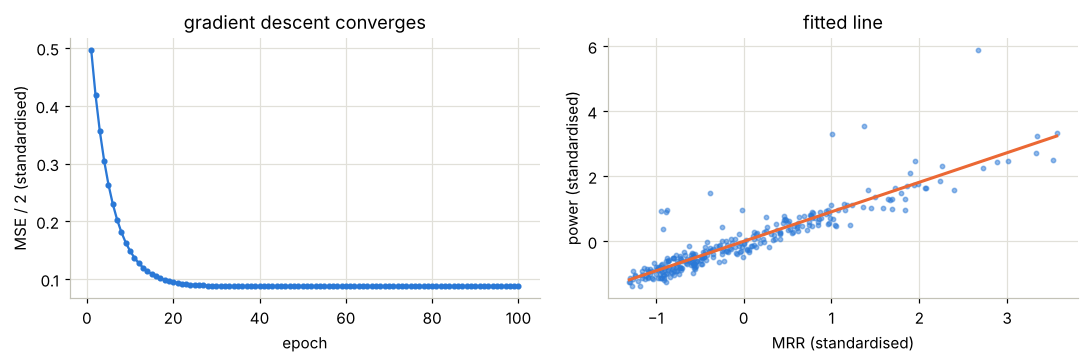

slope     : 18.33 W per cm³/min
intercept : 504 W


In [8]:
from sklearn.preprocessing import StandardScaler

sc_x, sc_y = StandardScaler(), StandardScaler()
X1_std = sc_x.fit_transform(X1)
y1_std = sc_y.fit_transform(y1[:, None]).ravel()

gd = LinearRegressionGD(eta=0.1, n_iter=100).fit(X1_std, y1_std)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(range(1, gd.n_iter + 1), gd.losses_, "o-", color=BLUE, ms=3)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("MSE / 2 (standardised)"); ax[0].set_title("gradient descent converges")
order = np.argsort(X1_std[:, 0])
ax[1].scatter(X1_std, y1_std, s=8, color=BLUE, alpha=0.5)
ax[1].plot(X1_std[order], gd.predict(X1_std[order]), color=ORANGE, lw=2)
ax[1].set_xlabel("MRR (standardised)"); ax[1].set_ylabel("power (standardised)")
ax[1].set_title("fitted line")
plt.tight_layout(); savefig("ch03_gd_fit"); plt.show()

# back to engineering units
w_W_per_cm3min = gd.w_[0] * sc_y.scale_[0] / sc_x.scale_[0]
b_W = sc_y.mean_[0] + sc_y.scale_[0] * gd.b_ - w_W_per_cm3min * sc_x.mean_[0]
print(f"slope     : {w_W_per_cm3min:.2f} W per cm³/min")
print(f"intercept : {b_W:.0f} W")

**The slope has a physical meaning.** 1 cm³/min = 1000/60 mm³/s, so a slope of $w$ W per
cm³/min corresponds to an effective specific energy of $w \cdot 60/1000$ J/mm³. The true value in
the simulator is $0.8/0.85 \approx 0.94$ J/mm³ for a new tool, rising with wear.

In [9]:
print(f"effective specific energy from the fit: {w_W_per_cm3min * 60 / 1000:.3f} J/mm³")
print(f"true (new tool) u / efficiency        : {0.8 / DRIVE_EFF:.3f} J/mm³;  "
      f"at average wear: {0.8 / DRIVE_EFF * (1 + 0.0012 * 125) * (1 - 0.03 * 0.7):.3f} J/mm³")

effective specific energy from the fit: 1.100 J/mm³
true (new tool) u / efficiency        : 0.941 J/mm³;  at average wear: 1.060 J/mm³


---
## 4. The normal equations, and scikit-learn

For least squares we do not actually need to iterate. Append a column of ones to $X$ so that the
bias becomes one more weight, $\boldsymbol\theta = [b, w]^\top$. Setting the gradient of
$\lVert \mathbf y - X\boldsymbol\theta\rVert^2$ to zero gives the **normal equations**
$$X^\top X\,\boldsymbol\theta = X^\top\mathbf y\quad\Longrightarrow\quad
\boldsymbol\theta = (X^\top X)^{-1}X^\top\mathbf y .$$
In code, never form the inverse explicitly — use a least-squares solver, which is faster and
numerically safer.

In [10]:
from sklearn.linear_model import LinearRegression

Xb = np.column_stack([np.ones(len(X1)), X1])
theta = np.linalg.lstsq(Xb, y1, rcond=None)[0]
slr = LinearRegression().fit(X1, y1)

print(f"gradient descent : w = {w_W_per_cm3min:8.3f}   b = {b_W:8.2f}")
print(f"normal equations : w = {theta[1]:8.3f}   b = {theta[0]:8.2f}")
print(f"scikit-learn     : w = {slr.coef_[0]:8.3f}   b = {slr.intercept_:8.2f}")

gradient descent : w =   18.331   b =   503.97
normal equations : w =   18.332   b =   503.96
scikit-learn     : w =   18.332   b =   503.96


All three agree. Gradient descent earns its place when $X^\top X$ is too large to solve directly
(millions of features) or when the model is not linear — which is every neural network from
Chapter 7 on.

---
## 5. Outliers and RANSAC

Least squares squares the residuals, so a few large ones — the chatter cuts — pull the line
toward them. **RANSAC** (RANdom SAmple Consensus) fits on random small subsets, counts how many
points agree with each fit (the *inliers*, residual below a threshold), and keeps the fit with
the largest consensus.

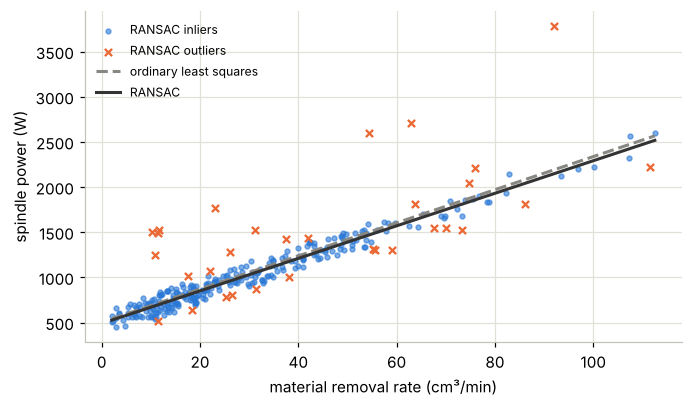

OLS    slope 18.33  intercept 504
RANSAC slope 18.02  intercept 489
chatter cuts flagged as outliers: 10 of 10
normal cuts flagged as outliers : 21 of 285


In [11]:
from sklearn.linear_model import RANSACRegressor

ransac = RANSACRegressor(LinearRegression(), max_trials=200, min_samples=30,
                         residual_threshold=150.0, random_state=0).fit(X1, y1)
inl = ransac.inlier_mask_

xs = np.linspace(X1.min(), X1.max(), 50)[:, None]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.scatter(X1[inl], y1[inl], s=10, color=BLUE, alpha=0.6, label="RANSAC inliers")
ax.scatter(X1[~inl], y1[~inl], s=22, color=ORANGE, marker="x", label="RANSAC outliers")
ax.plot(xs, slr.predict(xs), color=MUTED, lw=2, ls="--", label="ordinary least squares")
ax.plot(xs, ransac.predict(xs), color="#333", lw=2, label="RANSAC")
ax.set_xlabel("material removal rate (cm³/min)"); ax.set_ylabel("spindle power (W)"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("ch03_ransac"); plt.show()

truth = alu.chatter.to_numpy()
print(f"OLS    slope {slr.coef_[0]:.2f}  intercept {slr.intercept_:.0f}")
print(f"RANSAC slope {ransac.estimator_.coef_[0]:.2f}  intercept {ransac.estimator_.intercept_:.0f}")
print(f"chatter cuts flagged as outliers: {np.sum(~inl & truth)} of {truth.sum()}")
print(f"normal cuts flagged as outliers : {np.sum(~inl & ~truth)} of {(~truth).sum()}")

The outlier list is a by-product worth having: on a real cell those are exactly the cuts to send
to the process engineer. Choosing `residual_threshold` is engineering judgement — here 150 W,
roughly three times the measurement noise at mid-range power.

---
## 6. Multiple regression and how to evaluate it

Now use **all** cuts, both materials, and every raw column as a feature:
$$\hat y = b + w_1 x_1 + w_2 x_2 + \dots + w_m x_m .$$
`material` is categorical, so it becomes a 0/1 **indicator** column (`steel`). We hold out 30 % of
the cuts as a test set.

Three metrics:

* **MSE** $= \frac1n\sum (y-\hat y)^2$ — the quantity least squares minimises; units W².
* **MAE** $= \frac1n\sum |y-\hat y|$ — in watts, easy to explain, less sensitive to outliers.
* $R^2 = 1 - \dfrac{\text{MSE}}{\operatorname{Var}(y)}$ — the fraction of variance explained;
  1 is perfect, 0 is "no better than predicting the mean".

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

log["steel"] = (log.material == "steel").astype(int)
raw_feats = ["spindle_rpm", "feed_mm_min", "depth_mm", "width_mm", "tool_wear_um", "coolant", "steel"]

train, test = train_test_split(log, test_size=0.3, random_state=RANDOM_STATE)
ytr, yte = train.power_W.to_numpy(), test.power_W.to_numpy()
clean_te = ~test.chatter.to_numpy()     # hidden simulator truth, used ONLY for one extra score


def report(name, model, Xtr, Xte):
    pt, pe = model.predict(Xtr), model.predict(Xte)
    return dict(model=name,
                train_MAE_W=mean_absolute_error(ytr, pt), test_MAE_W=mean_absolute_error(yte, pe),
                train_R2=r2_score(ytr, pt), test_R2=r2_score(yte, pe),
                test_R2_no_chatter=r2_score(yte[clean_te], pe[clean_te]))


mlr_raw = LinearRegression().fit(train[raw_feats], ytr)
results = [report("linear, 7 raw features", mlr_raw, train[raw_feats], test[raw_feats])]
pd.DataFrame(results).set_index("model").round(3)

,train_MAE_W,test_MAE_W,train_R2,test_R2,test_R2_no_chatter
model,,,,,
"linear, 7 raw features",160.541,168.436,0.745,0.682,0.827


Two things to notice. First, the chatter cuts that are still in the data hurt every squared-error
score: the last column, which uses the simulator's hidden chatter flag to score only the normal
test cuts, is noticeably higher. A real cell does not have that flag, which is why §5's outlier
list matters. Second, even on clean cuts $R^2$ is mediocre. The **residual plot** — residual against prediction —
tells the real story. A good model leaves residuals scattered evenly around zero with no shape.

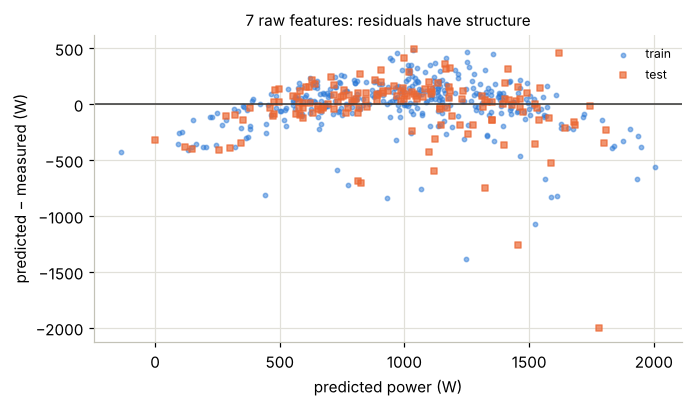

In [13]:
def residual_plot(ax, model, Xtr, Xte, title):
    pt, pe = model.predict(Xtr), model.predict(Xte)
    ax.scatter(pt, pt - ytr, s=8, color=BLUE, alpha=0.5, label="train")
    ax.scatter(pe, pe - yte, s=12, color=ORANGE, alpha=0.7, marker="s", label="test")
    ax.axhline(0, color="#333", lw=1)
    ax.set_xlabel("predicted power (W)"); ax.set_ylabel("predicted − measured (W)")
    ax.set_title(title, fontsize=10); ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(6.4, 3.8))
residual_plot(ax, mlr_raw, train[raw_feats], test[raw_feats], "7 raw features: residuals have structure")
plt.tight_layout(); savefig("ch03_resid_raw"); plt.show()

A clear pattern: the residuals form an **arch** — the model over-predicts mid-range cuts and
under-predicts both the lightest and the heaviest ones (the long tail far below zero is the chatter
cuts). The model
is **misspecified** — it is trying to express a *product* of features as a *sum* of features,
and it cannot. Adding more raw columns will not fix this.

---
## 7. Features from physics

We know the physics: power ≈ idle(rpm) + $u_\text{material}$ × MRR × wear factor. So build the
features the physics asks for:

* `mrr` = depth × width × feed,
* `mrr_steel` = `mrr` × `steel` (a different slope for each material — an **interaction**),
* `mrr_wear` = `mrr` × wear (wear increases the energy per mm³),
* and keep `spindle_rpm` for the idle power.

The model is *still linear in its weights*; only the inputs changed. That is why it is still
called linear regression.

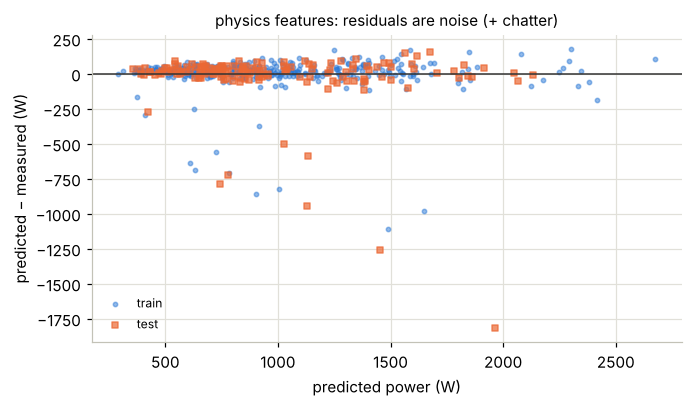

,train_MAE_W,test_MAE_W,train_R2,test_R2,test_R2_no_chatter
model,,,,,
"linear, 7 raw features",160.541,168.436,0.745,0.682,0.827
"linear, 5 physics features",58.689,84.146,0.912,0.791,0.985
"random forest, 7 raw features",59.158,145.444,0.947,0.725,0.886


In [14]:
def physics_features(d):
    mrr = d.depth_mm * d.width_mm * d.feed_mm_min / 1000.0
    return pd.DataFrame(dict(mrr=mrr, mrr_steel=mrr * d.steel, mrr_wear=mrr * d.tool_wear_um,
                             mrr_coolant=mrr * d.coolant, spindle_rpm=d.spindle_rpm))

Ftr, Fte = physics_features(train), physics_features(test)
mlr_phys = LinearRegression().fit(Ftr, ytr)
results.append(report("linear, 5 physics features", mlr_phys, Ftr, Fte))

from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0).fit(train[raw_feats], ytr)
results.append(report("random forest, 7 raw features", rf, train[raw_feats], test[raw_feats]))

fig, ax = plt.subplots(figsize=(6.4, 3.8))
residual_plot(ax, mlr_phys, Ftr, Fte, "physics features: residuals are noise (+ chatter)")
plt.tight_layout(); savefig("ch03_resid_phys"); plt.show()
pd.DataFrame(results).set_index("model").round(3)

In [15]:
coef = pd.Series(mlr_phys.coef_, index=Ftr.columns)
print(coef.round(4))
u_alu = coef.mrr * 60 / 1000
u_steel = (coef.mrr + coef.mrr_steel) * 60 / 1000
print(f"\nrecovered specific energy  aluminium {u_alu:.2f} J/mm³   steel {u_steel:.2f} J/mm³")
print(f"simulator (new tool, dry)  aluminium {0.8/DRIVE_EFF:.2f} J/mm³   steel {2.6/DRIVE_EFF:.2f} J/mm³")
print(f"idle power slope {coef.spindle_rpm:.4f} W/rpm   (simulator: 0.035)")

mrr            15.1955
mrr_steel      40.8701
mrr_wear        0.0238
mrr_coolant    -0.6319
spindle_rpm     0.0327
dtype: float64

recovered specific energy  aluminium 0.91 J/mm³   steel 3.36 J/mm³
simulator (new tool, dry)  aluminium 0.94 J/mm³   steel 3.06 J/mm³
idle power slope 0.0327 W/rpm   (simulator: 0.035)


Five well-chosen features beat seven raw ones by a wide margin (compare the clean-cut $R^2$), beat a 300-tree random forest on
the raw features, and every weight is a **physical constant you can check** against a machining
handbook. (The steel value comes out about 10 % high: the chatter cuts left in the training set
pull it up. Refit after removing RANSAC outliers and it moves back toward the true value.)
That is the strongest argument for knowing your process before you fit models to it.

---
## 8. Regularisation: Ridge and Lasso

When features are many or correlated, least-squares weights become large and unstable.
Regularisation adds a penalty on the weights:

* **Ridge** (L2): minimise $\text{MSE} + \alpha\lVert\mathbf w\rVert_2^2$ — shrinks all weights smoothly.
* **Lasso** (L1): minimise $\text{MSE} + \alpha\lVert\mathbf w\rVert_1$ — drives some weights
  **exactly to zero**, i.e. performs feature selection.

The penalty treats all weights alike, so features **must be standardised** first. Below we give
Lasso a deliberately bloated candidate set — every raw feature, every pairwise product of them —
and let it choose.

candidate features: 28


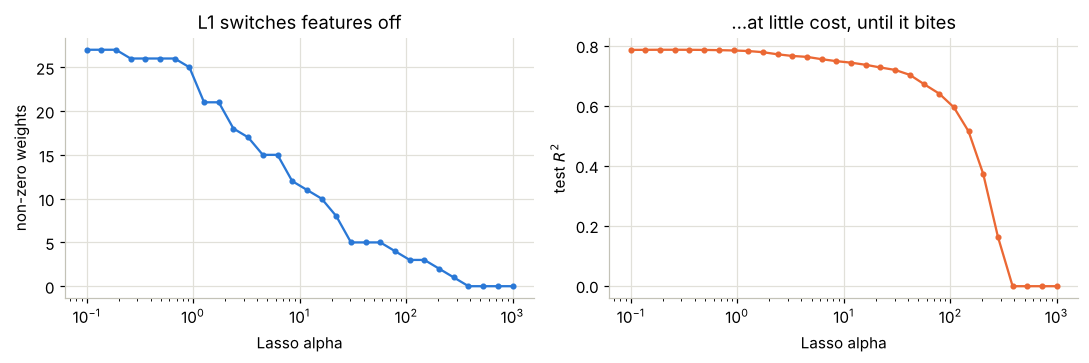


features Lasso kept at alpha = 20 (largest |weight| first):
depth_mm width_mm           203.7
feed_mm_min depth_mm        143.9
feed_mm_min width_mm        140.6
feed_mm_min steel            99.6
depth_mm tool_wear_um        43.3
feed_mm_min tool_wear_um      7.8
coolant steel                -7.4
width_mm tool_wear_um         2.4


,train_MAE_W,test_MAE_W,train_R2,test_R2,test_R2_no_chatter
model,,,,,
"linear, 7 raw features",160.541,168.436,0.745,0.682,0.827
"linear, 5 physics features",58.689,84.146,0.912,0.791,0.985
"random forest, 7 raw features",59.158,145.444,0.947,0.725,0.886
Lasso on 28 pairwise products,124.952,145.181,0.830,0.729,0.897
Ridge on 28 pairwise products,79.920,103.612,0.901,0.784,0.964


In [16]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Lasso, Ridge

poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
Ptr = poly.fit_transform(train[raw_feats]); Pte = poly.transform(test[raw_feats])
names = poly.get_feature_names_out(raw_feats)
print("candidate features:", Ptr.shape[1])

alphas = np.logspace(-1, 3, 30)
n_nonzero, test_r2 = [], []
for a in alphas:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=50000)).fit(Ptr, ytr)
    n_nonzero.append(np.sum(m[-1].coef_ != 0)); test_r2.append(r2_score(yte, m.predict(Pte)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(alphas, n_nonzero, "o-", color=BLUE, ms=3); ax[0].set_xscale("log")
ax[0].set_xlabel("Lasso alpha"); ax[0].set_ylabel("non-zero weights"); ax[0].set_title("L1 switches features off")
ax[1].plot(alphas, test_r2, "o-", color=ORANGE, ms=3); ax[1].set_xscale("log")
ax[1].set_xlabel("Lasso alpha"); ax[1].set_ylabel("test $R^2$"); ax[1].set_title("…at little cost, until it bites")
plt.tight_layout(); savefig("ch03_lasso"); plt.show()

lasso = make_pipeline(StandardScaler(), Lasso(alpha=20.0, max_iter=50000)).fit(Ptr, ytr)
kept = pd.Series(lasso[-1].coef_, index=names)
print("\nfeatures Lasso kept at alpha = 20 (largest |weight| first):")
print(kept[kept != 0].sort_values(key=np.abs, ascending=False).round(1).to_string())
results.append(report("Lasso on 28 pairwise products", lasso, Ptr, Pte))
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(Ptr, ytr)
results.append(report("Ridge on 28 pairwise products", ridge, Ptr, Pte))
pd.DataFrame(results).set_index("model").round(3)

Without being told the physics, Lasso puts most of its weight on the products that contain the
MRR ingredients (feed × depth, feed × width, depth × width with steel …). Pairwise products
cannot express the full three-way product, so it does not quite reach the physics model — but it
points you to where the structure is.

---
## 9. Nonlinear relationships: locally weighted regression

Some relationships are not linear in *any* simple set of features. A classic in robotics is the
**friction torque of a joint** as a function of velocity — the Stribeck curve: high static
friction at standstill, a dip as a lubricating film forms, then viscous friction growing
linearly:
$$\tau_f(\dot q) = \operatorname{sign}(\dot q)\Big[\tau_C + (\tau_S-\tau_C)\,e^{-(\dot q/v_S)^2}\Big] + \beta\,\dot q .$$
Identifying this curve matters for friction compensation in the joint controller.

**Locally weighted regression (LWR)** fits a *separate* straight line for every query point
$x_q$, weighting each training sample by how close it is:
$$w^{(i)} = \exp\!\left(-\frac{(x^{(i)}-x_q)^2}{2\tau^2}\right),\qquad
\boldsymbol\theta(x_q) = (X^\top W X)^{-1}X^\top W\mathbf y .$$
The bandwidth $\tau$ plays the role `gamma` played for the RBF SVM in Chapter 2.

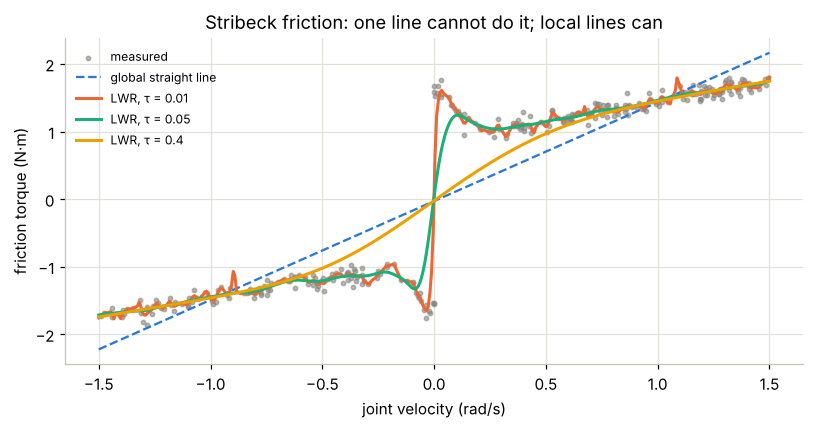

In [17]:
def make_friction_data(n=300, seed=4):
    rng = np.random.default_rng(seed)
    v = rng.uniform(-1.5, 1.5, n)                              # joint velocity, rad/s
    tau_c, tau_s, v_s, beta = 0.9, 1.6, 0.12, 0.55
    tau = np.sign(v) * (tau_c + (tau_s - tau_c) * np.exp(-(v / v_s) ** 2)) + beta * v
    return v, tau + rng.normal(0, 0.08, n)                     # N·m


def lwr_predict(xq, x, y, tau):
    Xb = np.column_stack([np.ones_like(x), x])
    out = np.empty_like(xq)
    for k, q in enumerate(xq):
        w = np.exp(-(x - q) ** 2 / (2 * tau ** 2))
        A = Xb.T @ (w[:, None] * Xb)
        out[k] = np.array([1.0, q]) @ np.linalg.solve(A + 1e-9 * np.eye(2), Xb.T @ (w * y))
    return out


v, tau_f = make_friction_data()
vq = np.linspace(-1.5, 1.5, 400)
lin = LinearRegression().fit(v[:, None], tau_f)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(v, tau_f, s=8, color=MUTED, alpha=0.6, label="measured")
ax.plot(vq, lin.predict(vq[:, None]), color=BLUE, lw=1.5, ls="--", label="global straight line")
for t, col in [(0.01, ORANGE), (0.05, AQUA), (0.4, YELLOW)]:
    ax.plot(vq, lwr_predict(vq, v, tau_f, t), color=col, lw=2, label=f"LWR, τ = {t}")
ax.set_xlabel("joint velocity (rad/s)"); ax.set_ylabel("friction torque (N·m)"); ax.legend(fontsize=8)
ax.set_title("Stribeck friction: one line cannot do it; local lines can")
plt.tight_layout(); savefig("ch03_lwr"); plt.show()

* **τ too small (0.01)** — each local line sees only a handful of points; the curve is noisy.
* **τ ≈ 0.05** — follows the stiction peak and the viscous slope.
* **τ too large (0.4)** — every local fit sees most of the data; the sharp jump at zero is
  smeared out.

LWR is **non-parametric**: it keeps all the training data and solves a small least-squares
problem per query — the same storage-versus-flexibility trade-off as k-NN.

---
## Summary

* Linear regression minimises squared error; gradient descent and the normal equations reach
  the same answer.
* Squared error is sensitive to outliers; **RANSAC** gives a robust fit and a list of suspicious
  cuts for free.
* Judge a model by its **residual plot**, not only by $R^2$.
* **Physics-informed features** (MRR, material interaction) beat both raw features and a
  black-box forest here, and give interpretable constants.
* **Regularisation** (Ridge, Lasso) tames large feature sets; Lasso also selects features.
* **LWR** handles strongly nonlinear 1-D relationships such as joint friction.

## Exercises

1. Fit `LinearRegressionGD` on *unscaled* MRR and power. Find the largest learning rate that
   still converges and explain the number.
2. Rerun RANSAC with `residual_threshold` = 50 W and 400 W. How do the inlier counts and the
   slope change?
3. Add `mrr_steel_wear` (MRR × steel × wear) to the physics features. Does the test MAE improve?
   Does the coefficient make physical sense?
4. Use the physics model's residuals to build a "tool needs checking" alarm: what residual
   threshold flags most chatter cuts while flagging fewer than 2 % of normal cuts?
5. Fit the Stribeck model directly with `scipy.optimize.curve_fit` and compare the parameters
   with the simulator's. When would you prefer that over LWR?